# Feature Engineering & Preprocessing Pipeline

A leak-free scikit-learn preprocessing pipeline for a tabular **credit default risk** dataset: feature encoding, scaling, missing-value imputation, and correlation / feature-importance analysis.

**Design principles used throughout:**
1. **Split first.** `train_test_split` happens before any imputer, scaler, or encoder ever sees the data.
2. **Fit on train, transform on both.** Every learned statistic (medians, means/stds, category vocab) comes from `X_train` only.
3. **Everything lives inside a `Pipeline`/`ColumnTransformer`**, so it is a single reusable object — and so that cross-validation refits preprocessing *inside* each fold, not once on the whole dataset.


## 1. Imports & configuration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, accuracy_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

## 2. Load the dataset

We use a synthetically generated **Credit Default Risk** dataset (5,000 rows) that mimics a realistic lending table: numeric fields (income, credit score, debt-to-income, etc.), categorical fields (employment type, home ownership, loan purpose, region), a binary `default` target, and injected missing values — so the notebook demonstrates real imputation rather than a toy problem with no missingness.

The generator function is defined directly in the cell below (no external file needed, so the notebook runs standalone anywhere). **To use a real dataset instead**, just replace the call to `make_credit_default_dataset(...)` with `df = pd.read_csv("your_file.csv")` — the rest of the pipeline (Sections 3 onward) works unchanged as long as you update the `numeric_features` / `categorical_features` lists in Section 4 to match your columns.

In [2]:
def make_credit_default_dataset(n_samples=5000, random_state=42):
    rng = np.random.default_rng(random_state)

    age = rng.normal(40, 12, n_samples).clip(18, 80)
    income = rng.lognormal(mean=10.8, sigma=0.55, size=n_samples).clip(12000, 400000)
    credit_score = rng.normal(650, 90, n_samples).clip(300, 850)
    debt_to_income = rng.beta(2, 5, n_samples) * 0.9
    num_credit_lines = rng.poisson(4, n_samples).clip(0, 20)
    years_employed = rng.exponential(6, n_samples).clip(0, 40)
    late_payments_2y = rng.poisson(0.8, n_samples).clip(0, 15)
    loan_amount = rng.lognormal(mean=9.5, sigma=0.6, size=n_samples).clip(1000, 150000)

    employment_type = rng.choice(
        ["Salaried", "Self-Employed", "Unemployed", "Retired"],
        size=n_samples, p=[0.55, 0.25, 0.08, 0.12]
    )
    home_ownership = rng.choice(
        ["Rent", "Mortgage", "Own"], size=n_samples, p=[0.4, 0.4, 0.2]
    )
    loan_purpose = rng.choice(
        ["Debt Consolidation", "Home Improvement", "Auto", "Medical", "Business", "Other"],
        size=n_samples, p=[0.30, 0.15, 0.20, 0.10, 0.15, 0.10]
    )
    region = rng.choice(["North", "South", "East", "West"], size=n_samples)

    # latent risk score drives the target -> creates genuine, learnable signal
    risk_score = (
        -0.020 * (credit_score - 650)
        + 3.0 * debt_to_income
        + 0.35 * late_payments_2y
        - 0.00002 * income
        + 0.05 * (loan_amount / (income + 1))
        - 0.05 * years_employed
        + (employment_type == "Unemployed") * 1.4
        + (home_ownership == "Rent") * 0.25
        + rng.normal(0, 0.8, n_samples)
    )
    default_prob = 1 / (1 + np.exp(-(risk_score - 1.2)))
    default = rng.binomial(1, default_prob)

    df = pd.DataFrame({
        "age": age,
        "annual_income": income,
        "credit_score": credit_score,
        "debt_to_income_ratio": debt_to_income,
        "num_credit_lines": num_credit_lines,
        "years_employed": years_employed,
        "late_payments_2y": late_payments_2y,
        "loan_amount": loan_amount,
        "employment_type": employment_type,
        "home_ownership": home_ownership,
        "loan_purpose": loan_purpose,
        "region": region,
        "default": default,
    })

    # inject realistic missingness (MCAR/MAR-ish) into several columns
    for col, frac in [
        ("annual_income", 0.06),
        ("credit_score", 0.04),
        ("years_employed", 0.08),
        ("employment_type", 0.03),
        ("home_ownership", 0.05),
        ("debt_to_income_ratio", 0.05),
    ]:
        mask = rng.random(n_samples) < frac
        df.loc[mask, col] = np.nan

    return df


df = make_credit_default_dataset(n_samples=5000, random_state=RANDOM_STATE)

print(f"Dataset shape: {df.shape}")
print(f"\nTarget balance:\n{df['default'].value_counts(normalize=True).round(3)}")
print(f"\nDtypes:\n{df.dtypes}")
print("\nFirst rows:")
print(df.head())

Dataset shape: (5000, 13)

Target balance:
default
0    0.695
1    0.305
Name: proportion, dtype: float64

Dtypes:
age                     float64
annual_income           float64
credit_score            float64
debt_to_income_ratio    float64
num_credit_lines          int64
years_employed          float64
late_payments_2y          int64
loan_amount             float64
employment_type             str
home_ownership              str
loan_purpose                str
region                      str
default                   int64
dtype: object

First rows:
         age  annual_income  credit_score  debt_to_income_ratio  num_credit_lines  years_employed  late_payments_2y  \
0  43.656605   42536.863214    665.864933              0.295965                 7             NaN                 2   
1  27.520191   41576.183075           NaN              0.258530                 4        3.459736                 1   
2  49.005414   33417.568649    517.495645              0.121009                 7    

### 2.1 Missing-value audit
Check what's missing and where, *before* deciding on an imputation strategy per column type.

In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_report = pd.DataFrame({"n_missing": missing, "pct_missing": missing_pct})
print(missing_report[missing_report["n_missing"] > 0].sort_values("pct_missing", ascending=False))

                      n_missing  pct_missing
years_employed              404         8.08
annual_income               292         5.84
home_ownership              260         5.20
debt_to_income_ratio        239         4.78
credit_score                198         3.96
employment_type             147         2.94


## 3. Train/test split — before any transformation
This is the step that prevents leakage: nothing downstream is allowed to look at `X_test` until final evaluation.

In [4]:
# ============================================================
# STEP 1: Train/test split BEFORE any preprocessing/fitting.
# This is the single most important leak-prevention step:
# every imputer/scaler/encoder statistic (means, medians, category
# vocabularies) below is learned ONLY from X_train.
# ============================================================
TARGET = "default"
X = df.drop(columns=[TARGET])
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Train default rate: {y_train.mean():.3f} | Test default rate: {y_test.mean():.3f}")

X_train: (4000, 12), X_test: (1000, 12)
Train default rate: 0.305 | Test default rate: 0.305


## 4. Build per-type preprocessing pipelines

- **Numeric columns** → median imputation (robust to outliers/skew) → `StandardScaler`
- **Categorical columns** → most-frequent imputation → `OneHotEncoder(handle_unknown="ignore")` so unseen categories at inference time don't crash the pipeline

Both are combined with a `ColumnTransformer`, which applies the right pipeline to the right columns and concatenates the result.

In [5]:
# ============================================================
# STEP 2: Identify column groups and build per-type pipelines.
# ============================================================
numeric_features = [
    "age", "annual_income", "credit_score", "debt_to_income_ratio",
    "num_credit_lines", "years_employed", "late_payments_2y", "loan_amount",
]
categorical_features = [
    "employment_type", "home_ownership", "loan_purpose", "region",
]

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

preprocessor

## 5. Fit on train only, transform both
`fit_transform` is called on `X_train`; `X_test` only ever gets `.transform()`. No statistic from the test set leaks into training.

In [6]:
# ============================================================
# STEP 3: Fit the preprocessor on TRAIN ONLY, then transform
# both train and test with those learned statistics.
# ============================================================
X_train_proc = preprocessor.fit_transform(X_train, y_train)
X_test_proc = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

X_train_proc_df = pd.DataFrame(X_train_proc, columns=feature_names, index=X_train.index)
X_test_proc_df = pd.DataFrame(X_test_proc, columns=feature_names, index=X_test.index)

print(f"Transformed train shape: {X_train_proc_df.shape}")
print(f"Transformed test shape:  {X_test_proc_df.shape}")
print(f"\nAny NaNs left in train? {X_train_proc_df.isna().any().any()}")
print(f"Any NaNs left in test?  {X_test_proc_df.isna().any().any()}")
print("\nSample of transformed feature names:")
print(list(feature_names[:6]), "...", list(feature_names[-4:]))

Transformed train shape: (4000, 25)
Transformed test shape:  (1000, 25)

Any NaNs left in train? False
Any NaNs left in test?  False

Sample of transformed feature names:
['num__age', 'num__annual_income', 'num__credit_score', 'num__debt_to_income_ratio', 'num__num_credit_lines', 'num__years_employed'] ... ['cat__region_East', 'cat__region_North', 'cat__region_South', 'cat__region_West']


## 6. Correlation analysis
Computed on the **training set only**. This both guides feature selection and sanity-checks the synthetic signal (debt-to-income and late payments should correlate positively with default; credit score negatively).


Correlation with target, sorted:
credit_score           -0.483
annual_income          -0.163
late_payments_2y        0.120
debt_to_income_ratio    0.111
years_employed         -0.081
loan_amount            -0.007
num_credit_lines       -0.006
age                    -0.002
Name: default, dtype: float64


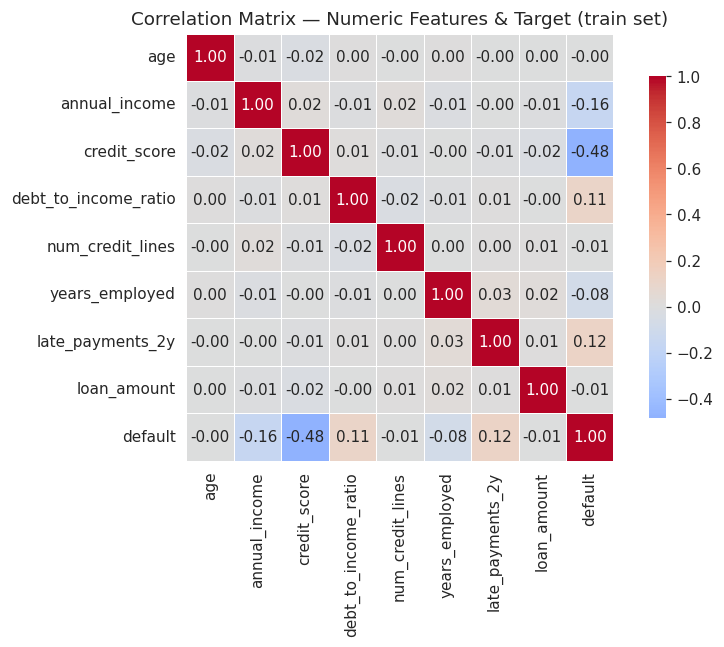

In [7]:
# ============================================================
# Correlation analysis (numeric features + target), computed on
# TRAIN data only to avoid any test-set peeking.
# ============================================================
corr_df = X_train[numeric_features].copy()
corr_df["default"] = y_train.values
corr_matrix = corr_df.corr()

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax
)
ax.set_title("Correlation Matrix — Numeric Features & Target (train set)")
plt.tight_layout()
plt.savefig("corr_heatmap.png", dpi=110, bbox_inches="tight")
plt.show()

print("\nCorrelation with target, sorted:")
print(corr_matrix["default"].drop("default").sort_values(key=abs, ascending=False).round(3))

## 7. Feature importance — mutual information
Mutual information captures non-linear relationships that a plain correlation coefficient would miss, and is computed on the transformed train matrix.

num__credit_score                     0.1325
cat__region_West                      0.0258
num__annual_income                    0.0149
cat__loan_purpose_Home Improvement    0.0129
cat__home_ownership_Own               0.0122
num__years_employed                   0.0113
cat__region_South                     0.0098
cat__employment_type_Unemployed       0.0077
cat__employment_type_Retired          0.0062
cat__region_East                      0.0054
dtype: float64


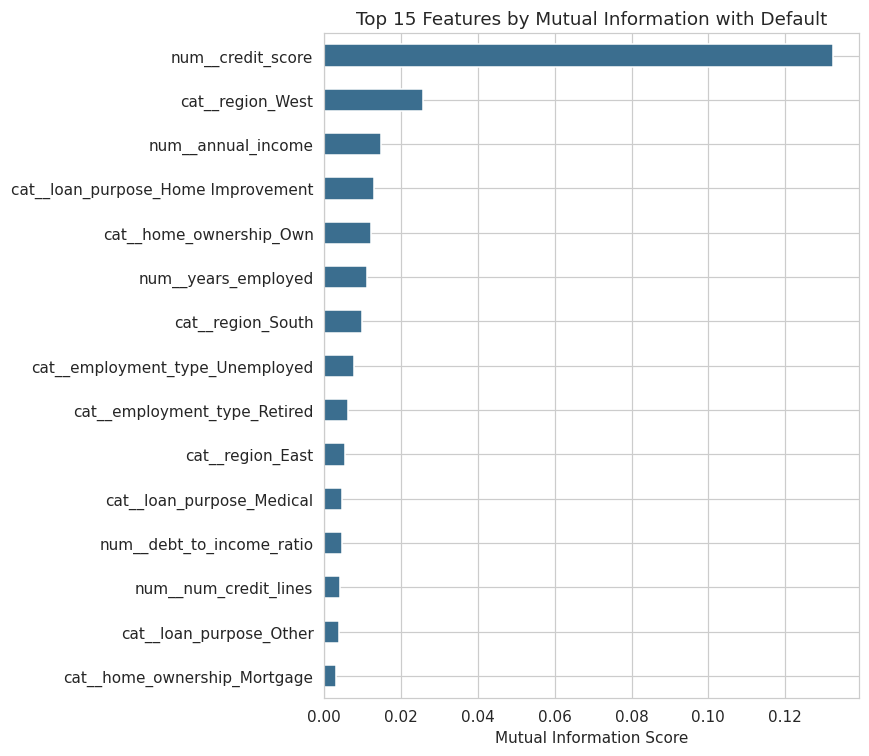

In [8]:
# ============================================================
# Feature importance #1: Mutual information (captures non-linear
# dependence too), computed on the transformed TRAIN features only.
# ============================================================
mi_scores = mutual_info_classif(X_train_proc_df, y_train, random_state=RANDOM_STATE)
mi_series = pd.Series(mi_scores, index=feature_names).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
mi_series.head(15).sort_values().plot(kind="barh", ax=ax, color="#3B6E8F")
ax.set_title("Top 15 Features by Mutual Information with Default")
ax.set_xlabel("Mutual Information Score")
plt.tight_layout()
plt.savefig("mi_importance.png", dpi=110, bbox_inches="tight")
plt.show()

print(mi_series.head(10).round(4))

## 8. Feature importance — tree-based, via full end-to-end pipeline
Here the preprocessor and a `RandomForestClassifier` are chained into **one** `Pipeline` object. Fitting it once fits both stages correctly and leak-free; it can be pickled, deployed, or handed to `GridSearchCV` as a single estimator.

Test accuracy: 0.783
Test ROC-AUC:  0.846

Classification report:
              precision    recall  f1-score   support

           0      0.791     0.935     0.857       695
           1      0.747     0.436     0.551       305

    accuracy                          0.783      1000
   macro avg      0.769     0.686     0.704      1000
weighted avg      0.777     0.783     0.764      1000

num__credit_score                  0.4811
num__annual_income                 0.0997
num__debt_to_income_ratio          0.0784
num__years_employed                0.0638
num__loan_amount                   0.0539
num__age                           0.0480
num__late_payments_2y              0.0339
cat__employment_type_Unemployed    0.0275
num__num_credit_lines              0.0265
cat__employment_type_Salaried      0.0068
dtype: float64


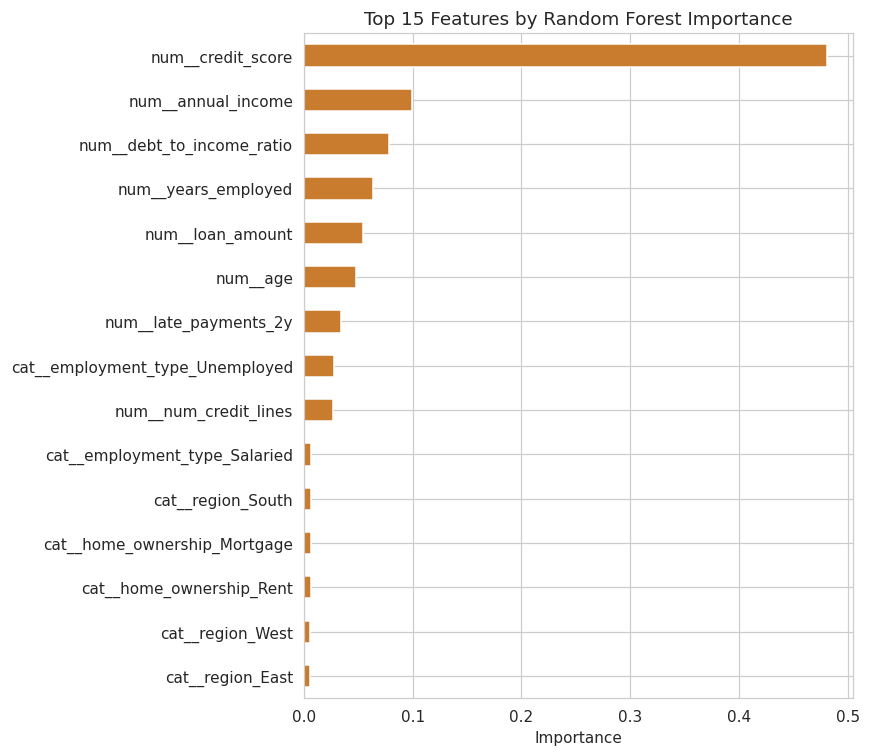

In [9]:
# ============================================================
# Feature importance #2: Tree-based, via a full end-to-end
# Pipeline(preprocessor -> classifier). The whole pipeline is
# fit ONLY on X_train / y_train.
# ============================================================
full_pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1
    )),
])

full_pipeline.fit(X_train, y_train)

y_pred = full_pipeline.predict(X_test)
y_proba = full_pipeline.predict_proba(X_test)[:, 1]

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")
print(f"Test ROC-AUC:  {roc_auc_score(y_test, y_proba):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, digits=3))

rf_importances = pd.Series(
    full_pipeline.named_steps["classifier"].feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
rf_importances.head(15).sort_values().plot(kind="barh", ax=ax, color="#C97B2E")
ax.set_title("Top 15 Features by Random Forest Importance")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig("rf_importance.png", dpi=110, bbox_inches="tight")
plt.show()

print(rf_importances.head(10).round(4))

## 9. Reusability & leakage check via cross-validation
`build_pipeline()` returns a **fresh, unfitted** pipeline. Running it through `cross_val_score` means preprocessing (imputer means, scaler stats, one-hot vocabulary) is refit independently inside every fold — the correct way to cross-validate when preprocessing has learned parameters.

In [10]:
# ============================================================
# Reusability check: wrap pipeline construction in a function and
# run stratified cross-validation. Because preprocessing lives
# INSIDE the pipeline, each CV fold refits imputers/scaler/encoder
# on that fold's training portion only -> no leakage across folds.
# ============================================================
def build_pipeline(n_estimators=300, max_depth=8, random_state=RANDOM_STATE):
    """Return a fresh, leak-free preprocessing + model pipeline."""
    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    preprocessor = ColumnTransformer(transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ])
    return Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=n_estimators, max_depth=max_depth,
            random_state=random_state, n_jobs=-1
        )),
    ])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(build_pipeline(), X_train, y_train, cv=cv, scoring="roc_auc")

print(f"5-fold CV ROC-AUC (train set, refit each fold): {cv_scores.round(3)}")
print(f"Mean: {cv_scores.mean():.3f}  Std: {cv_scores.std():.3f}")

5-fold CV ROC-AUC (train set, refit each fold): [0.849 0.828 0.819 0.826 0.809]
Mean: 0.826  Std: 0.013


## Summary

| Requirement | How it's satisfied |
|---|---|
| Complex tabular dataset | Synthetic Credit Default Risk table: 8 numeric + 4 categorical features, realistic missingness |
| `ColumnTransformer` + `Pipeline` for scaling & encoding | `numeric_pipeline` (median impute → scale) and `categorical_pipeline` (mode impute → one-hot) combined via `ColumnTransformer` |
| Split before any transform | `train_test_split` called first; all `fit`/`fit_transform` calls use only `X_train`/`y_train` |
| Feature importance | Mutual information (`mutual_info_classif`) **and** Random Forest `feature_importances_` |
| Reusable | `build_pipeline()` factory function + the pipeline object itself is a single, picklable, deployable estimator |

**Next steps for a production version:** hyperparameter search over the full pipeline with `GridSearchCV`/`RandomizedSearchCV` (safe because preprocessing is inside the pipeline), persisting with `joblib.dump`, and adding a `Pipeline`-compatible drift/monitoring step for the categorical vocabularies.
